# Etapa 1 — Dataset de Bonn y análisis de Fourier

**Fuente oficial:** Universitätsklinikum Bonn, Epileptologie, AG Lehnertz.
Andrzejak RG, Lehnertz K, Rieke C, Mormann F, David P, Elger CE (2001).
*Phys. Rev. E, 64, 061907*.

| Set | Archivo | Registro | Estado |
|---|---|---|---|
| A | Z | superficie, voluntarios sanos | ojos abiertos |
| B | O | superficie, voluntarios sanos | ojos cerrados |
| C | N | intracraneal, zona opuesta al foco | entre crisis (interictal) |
| D | F | intracraneal, zona epileptógena | entre crisis (interictal) |
| E | S | intracraneal | durante la crisis (ictal) |

Cada segmento: $N = 4097$ muestras a $f_s = 173{,}61$ Hz, o sea $T = N/f_s \approx 23{,}6$ s.
Ancho de banda del equipo: 0,5–85 Hz. El artículo aplica un pasabajos de 40 Hz como primer paso
del análisis; las series descargables **no** lo tienen aplicado.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

try:
    import google.colab  # noqa: F401
    RAIZ = Path("/content/drive/MyDrive/TP_Machine_Learning_Epilepsia")
except ImportError:
    RAIZ = Path.cwd().parents[0] if Path.cwd().name == "notebooks" else Path.cwd()

DATOS = RAIZ / "datos" / "bonn"
SALIDA = RAIZ / "resultados" / "etapa1"
SALIDA.mkdir(parents=True, exist_ok=True)

FS = 173.61
SETS = {"A": "Z", "B": "O", "C": "N", "D": "F", "E": "S"}
DESCRIPCION = {"A": "Sano, ojos abiertos", "B": "Sano, ojos cerrados",
               "C": "Interictal, zona opuesta", "D": "Interictal, zona epileptogena",
               "E": "Ictal (crisis)"}
print("RAIZ:", RAIZ)

RAIZ: D:\Universidad De Palermo - Maestria en IA\Machine Learning\TP_Machine_Learning_Epilepsia


## 1.1 Carga y verificación

In [2]:
def cargar_set(letra_archivo):
    archivos = sorted((DATOS / letra_archivo).glob("*.[tT][xX][tT]"))
    return np.stack([np.loadtxt(a) for a in archivos]), [a.name for a in archivos]

X, y, nombres = [], [], []
for s, letra in SETS.items():
    datos, n = cargar_set(letra)
    X.append(datos); y += [s] * len(datos); nombres += n
X = np.concatenate(X).astype(np.float32)
y = np.array(y)

assert X.shape == (500, 4097), X.shape
assert all((y == s).sum() == 100 for s in SETS)
print("X:", X.shape, "| duración por segmento: %.2f s" % (X.shape[1] / FS))
print("Nyquist: f_s/2 = %.2f Hz" % (FS / 2))

resumen = pd.DataFrame({
    "set": list(SETS), "descripcion": [DESCRIPCION[s] for s in SETS],
    "media_uV": [X[y == s].mean() for s in SETS],
    "desvio_uV": [X[y == s].std() for s in SETS],
    "max_abs_uV": [np.abs(X[y == s]).max() for s in SETS],
}).round(1)
resumen.to_csv(SALIDA / "resumen_sets.csv", index=False)
resumen

X: (500, 4097) | duración por segmento: 23.60 s
Nyquist: f_s/2 = 86.81 Hz


,set,descripcion,media_uV,desvio_uV,max_abs_uV
0,A,"Sano, ojos abiertos",-6.3,48.299999,294.0
1,B,"Sano, ojos cerrados",-12.5,70.699997,424.0
2,C,"Interictal, zona opuesta",-8.9,59.400002,623.0
3,D,"Interictal, zona epileptogena",-6.2,90.300003,2047.0
4,E,Ictal (crisis),-4.7,341.200012,2047.0


### Saturación del conversor

El valor 2047 es el máximo de un conversor de 12 bits con signo ($2^{11}-1$). Las muestras que llegan
a ese valor están **recortadas**: la amplitud real era mayor. Se cuentan, se documentan y se conservan
como vienen en la fuente oficial (no se corrigen).

In [3]:
TOPE = 2047
sat = np.abs(X) >= TOPE
tabla_sat = pd.DataFrame({
    "set": list(SETS),
    "segmentos_saturados": [int(sat[y == s].any(axis=1).sum()) for s in SETS],
    "muestras_saturadas": [int(sat[y == s].sum()) for s in SETS],
})
print("Segmentos afectados:", [nombres[i] for i in np.where(sat.any(axis=1))[0]])
tabla_sat.to_csv(SALIDA / "saturacion_12bits.csv", index=False)
tabla_sat

Segmentos afectados: ['F009.txt', 'S059.txt', 'S065.txt']


,set,segmentos_saturados,muestras_saturadas
0,A,0,0
1,B,0,0
2,C,0,0
3,D,1,52
4,E,2,20


## 1.2 Un ejemplo por set (los mismos que publica el grupo de Bonn)

Series de ejemplo oficiales: Z093, O015, N062, F021, S056.

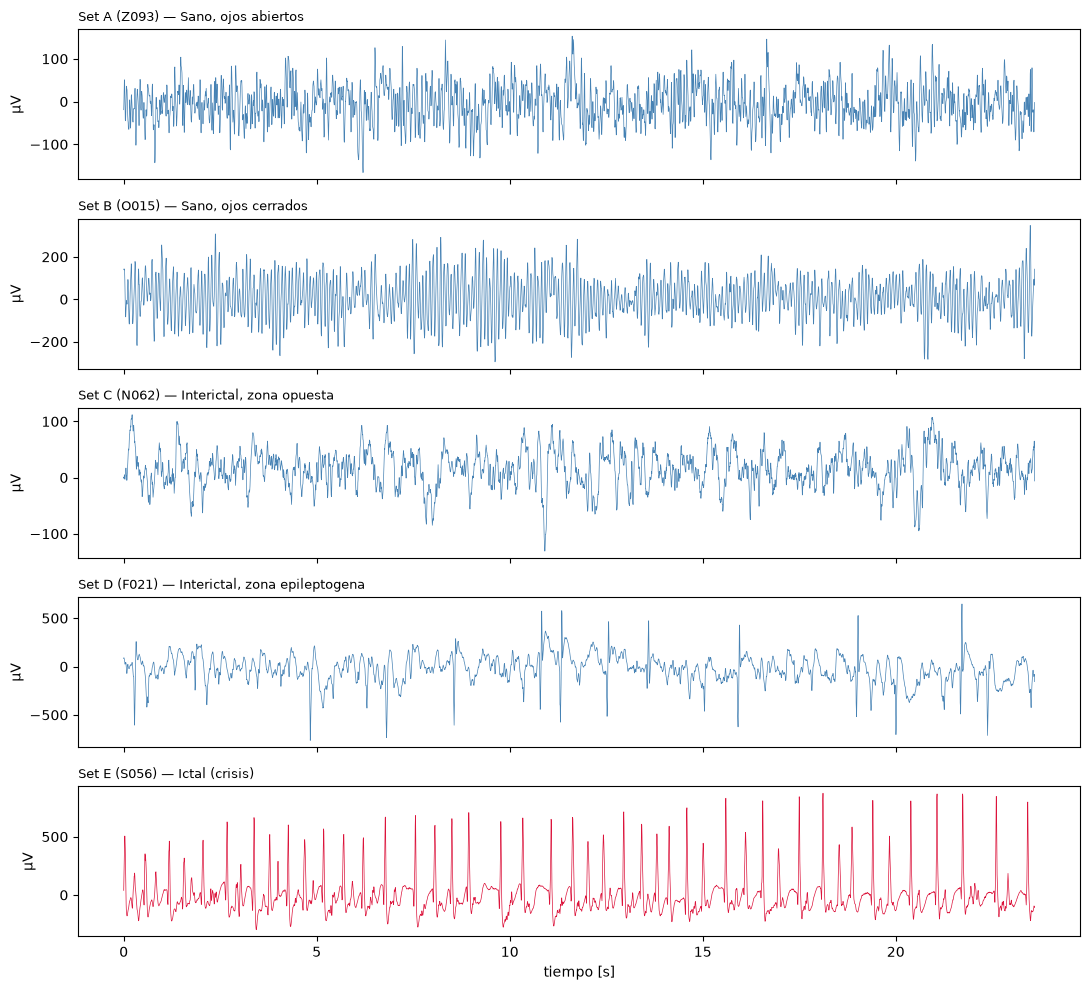

In [4]:
ejemplos = {"A": "Z093", "B": "O015", "C": "N062", "D": "F021", "E": "S056"}
t = np.arange(X.shape[1]) / FS
fig, ejes = plt.subplots(5, 1, figsize=(11, 10), sharex=True)
for ax, (s, nom) in zip(ejes, ejemplos.items()):
    i = [k for k, n in enumerate(nombres) if n.upper().startswith(nom)][0]
    ax.plot(t, X[i], lw=0.5, color="crimson" if s == "E" else "steelblue")
    ax.set_ylabel("µV"); ax.set_title(f"Set {s} ({nom}) — {DESCRIPCION[s]}", fontsize=9, loc="left")
ejes[-1].set_xlabel("tiempo [s]")
fig.tight_layout(); fig.savefig(SALIDA / "ejemplos_por_set.png", dpi=150)

## 1.3 Transformada discreta de Fourier

Para una señal muestreada $x[n]$, $n = 0,\dots,N-1$:

$$X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-j 2\pi k n / N}, \qquad f_k = \frac{k\, f_s}{N}.$$

La resolución en frecuencia es $\Delta f = f_s/N \approx 0{,}042$ Hz. Para reducir la varianza del
estimador se usa el método de Welch: se promedian periodogramas de ventanas de Hann con 50 % de solapamiento.

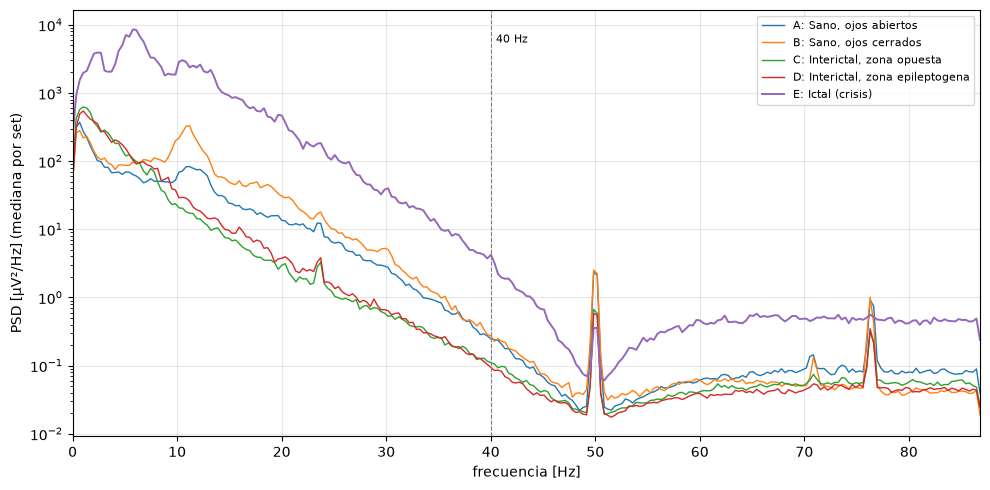

In [5]:
def psd_welch(x, nperseg=512):
    return signal.welch(x, fs=FS, window="hann", nperseg=nperseg, noverlap=nperseg // 2, axis=-1)

f, P = psd_welch(X)
fig, ax = plt.subplots(figsize=(10, 5))
for s in SETS:
    m = np.median(P[y == s], axis=0)
    ax.semilogy(f, m, label=f"{s}: {DESCRIPCION[s]}", lw=1.4 if s == "E" else 1)
ax.axvline(40, ls="--", c="gray", lw=0.8); ax.text(40.5, ax.get_ylim()[1] / 3, "40 Hz", fontsize=8)
ax.set_xlim(0, FS / 2); ax.set_xlabel("frecuencia [Hz]"); ax.set_ylabel("PSD [µV²/Hz] (mediana por set)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(SALIDA / "psd_welch_por_set.png", dpi=150)

**Observaciones del espectro:**
- El set E (crisis) tiene entre 10 y 100 veces más potencia que los demás entre 3 y 25 Hz, con un pico cerca de 6 Hz.
  Esa es la descarga rítmica de la crisis.
- El set B (ojos cerrados) muestra el ritmo **alfa** cerca de 10–11 Hz, que casi desaparece con los ojos abiertos (A).
- El pico en **50 Hz** es interferencia de la red eléctrica (Alemania, 50 Hz) y aparece en todos los sets.
  El pasabajos de 40 Hz lo elimina.
- El pico cerca de 76 Hz aparece sobre todo en los registros de superficie (A, B); también queda fuera con el filtro.

## 1.4 Filtro pasabajos de 40 Hz (primer paso del artículo original)

Butterworth de orden 4 aplicado ida y vuelta (`filtfilt`), así la fase no se distorsiona.

In [6]:
b, a = signal.butter(4, 40, btype="low", fs=FS)
Xf = signal.filtfilt(b, a, X, axis=-1).astype(np.float32)
f2, Pf = psd_welch(Xf)
print("Energía relativa por encima de 40 Hz (antes del filtro):")
for s in SETS:
    tot = np.trapezoid(P[y == s], f, axis=1); alta = np.trapezoid(P[y == s][:, f > 40], f[f > 40], axis=1)
    print(f"  {s}: {np.median(alta / tot) * 100:.2f} %")

Energía relativa por encima de 40 Hz (antes del filtro):
  A: 0.39 %
  B: 0.21 %
  C: 0.17 %
  D: 0.14 %
  E: 0.05 %


## 1.5 Potencia por bandas clínicas

$$P_{[f_1,f_2]} = \int_{f_1}^{f_2} S_{xx}(f)\, df \approx \sum_{f_1 \le f_k < f_2} S_{xx}(f_k)\, \Delta f$$

Bandas: delta 0,5–4, theta 4–8, alfa 8–13, beta 13–30, gamma 30–40 Hz.

,delta,theta,alfa,beta,gamma
set,,,,,
A,0.367,0.182,0.241,0.203,0.007
B,0.181,0.126,0.476,0.213,0.004
C,0.668,0.214,0.071,0.044,0.002
D,0.602,0.253,0.100,0.044,0.001
E,0.248,0.405,0.174,0.171,0.003


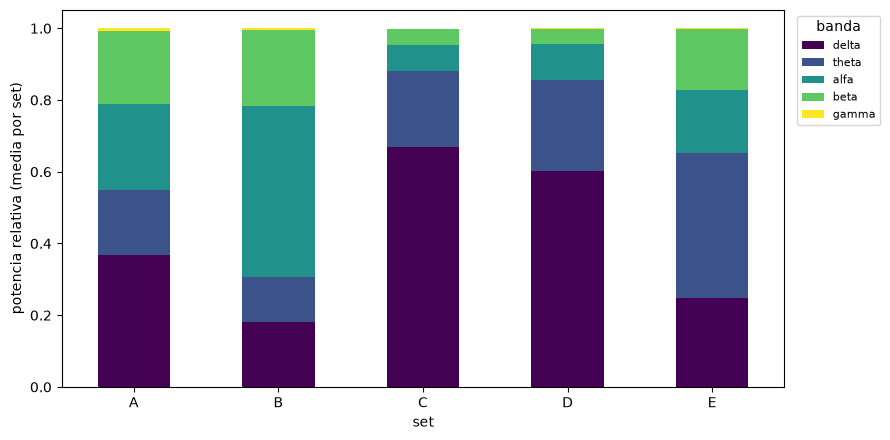

In [7]:
BANDAS = {"delta": (0.5, 4), "theta": (4, 8), "alfa": (8, 13), "beta": (13, 30), "gamma": (30, 40)}

def potencia_bandas(f, P):
    out = {}
    for nombre, (lo, hi) in BANDAS.items():
        m = (f >= lo) & (f < hi)
        out[nombre] = np.trapezoid(P[..., m], f[m], axis=-1)
    return pd.DataFrame(out)

bp = potencia_bandas(f2, Pf)
bp_rel = bp.div(bp.sum(axis=1), axis=0)
bp_rel["set"] = y
# La media por set conserva la suma = 1 (la mediana por banda no).
tabla = bp_rel.groupby("set").mean().round(3)
assert np.allclose(tabla.sum(axis=1), 1, atol=0.01)
tabla.to_csv(SALIDA / "potencia_relativa_bandas_media.csv")
bp_rel.groupby("set").median().round(3).to_csv(SALIDA / "potencia_relativa_bandas_mediana.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
tabla.plot(kind="bar", stacked=True, ax=ax, colormap="viridis", rot=0)
ax.set_ylabel("potencia relativa (media por set)"); ax.set_xlabel("set")
ax.legend(title="banda", fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout(); fig.savefig(SALIDA / "potencia_relativa_bandas.png", dpi=150)
tabla

## 1.6 Espectrograma (STFT) de un segmento ictal

$$\mathrm{STFT}\{x\}(m, k) = \sum_{n} x[n]\, w[n - mH]\, e^{-j 2\pi k n / L}$$

con ventana $w$ de largo $L$ y salto $H$. La STFT muestra cómo cambia el contenido en frecuencia a lo largo del tiempo.

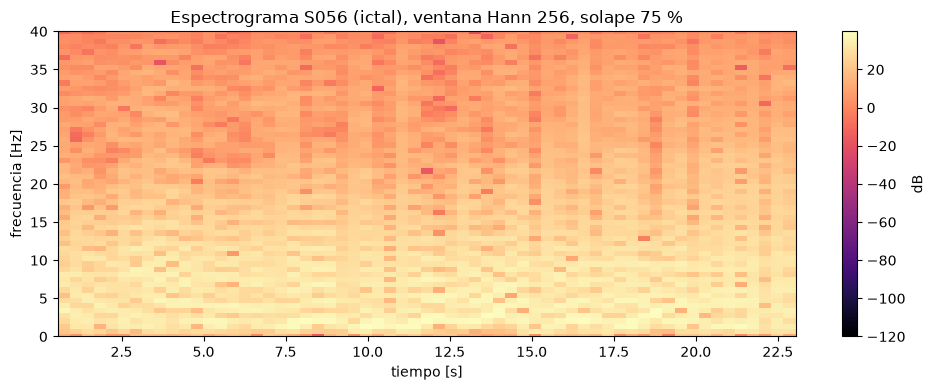

In [8]:
i = [k for k, n in enumerate(nombres) if n.upper().startswith("S056")][0]
fs_, ts_, Sxx = signal.spectrogram(Xf[i], fs=FS, window="hann", nperseg=256, noverlap=192)
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.pcolormesh(ts_, fs_, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma")
ax.set_ylim(0, 40); ax.set_xlabel("tiempo [s]"); ax.set_ylabel("frecuencia [Hz]")
ax.set_title("Espectrograma S056 (ictal), ventana Hann 256, solape 75 %")
fig.colorbar(im, label="dB"); fig.tight_layout(); fig.savefig(SALIDA / "espectrograma_S056.png", dpi=150)

## 1.7 Guardado para las etapas siguientes

In [9]:
np.savez_compressed(SALIDA / "bonn_filtrado_40hz.npz", X=Xf, y=y, nombres=np.array(nombres), fs=FS)
meta = {"fs": FS, "n_muestras": int(X.shape[1]), "n_segmentos": int(X.shape[0]),
        "filtro": "Butterworth orden 4, pasabajos 40 Hz, filtfilt",
        "welch": {"ventana": "hann", "nperseg": 512, "noverlap": 256},
        "fuente": "https://www.ukbonn.de/epileptologie/arbeitsgruppen/ag-lehnertz-neurophysik/downloads/"}
(SALIDA / "metadatos.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(sorted(p.name for p in SALIDA.iterdir()))

['bonn_filtrado_40hz.npz', 'ejemplos_por_set.png', 'espectrograma_S056.png', 'metadatos.json', 'potencia_relativa_bandas.png', 'potencia_relativa_bandas_media.csv', 'potencia_relativa_bandas_mediana.csv', 'psd_welch_por_set.png', 'resumen_sets.csv', 'saturacion_12bits.csv']
